In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
import os
from PIL import Image
import numpy as np
from tqdm import tqdm
from torch.utils.data import DataLoader
import torchvision.transforms as T
import matplotlib.pyplot as plt
import copy
from sklearn.metrics import f1_score, precision_score, recall_score

In [ ]:
from google.colab import drive
drive.mount("/content/gdrive")

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
import os
os.chdir('/content/gdrive/MyDrive/COMP448/hw3')

# Load Data

In [ ]:
train_dir = "images/tr"
val_dir = "images/val"
test_dir = "images/ts"
gold_dir = "golds"

In [ ]:
def get_images(image_dir, file_type=".jpg"):
    image_paths = sorted([os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith(file_type)])
    return image_paths


In [ ]:
train_images = get_images(train_dir)
val_images = get_images(val_dir)
test_images = get_images(test_dir)
gold_masks = get_images(gold_dir, file_type=".png")

print(f"Length of train images: {len(train_images)}")
print(f"Length of validation images: {len(val_images)}")
print(f"Length of test images: {len(test_images)}")

Length of train images: 119
Length of validation images: 56
Length of test images: 82


In [ ]:
def get_image_masks(image_paths, gold_mask_paths):

    mask_dict = dict()

    # Gold mask name structure: gold_*_Image_*.png
    for path in gold_mask_paths:
      base_name = os.path.basename(path).replace("gold_", "")
      mask_dict[base_name] = path

    image_masks = []
    missing_image_masks = []

    # Image name structure: CT_*_Image_*.jpg
    for path in image_paths:

        key = os.path.basename(path).replace("CT_", "").replace(".jpg", ".png")

        if key in mask_dict:
            image_masks.append(mask_dict[key])
        else:
            missing_image_masks.append(key)

    if len(missing_image_masks) != 0:
      print(f"Missing image masks: {image_masks}")

    return image_masks

In [ ]:
train_masks = get_image_masks(train_images, gold_masks)
val_masks = get_image_masks(val_images, gold_masks)
test_masks = get_image_masks(test_images, gold_masks)

# Create Dataset

In [ ]:
class HeartSegmentationDataset(Dataset):
    def __init__(self, image_paths, mask_paths, input_size=(512, 512), augmentation=False):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.input_size = input_size
        self.augmentation = augmentation

    def __len__(self):
        return len(self.image_paths)

    def transform(self, image, mask):

        # Resize image and ask
        image = T.Resize(self.input_size)(image)
        mask = T.Resize(self.input_size)(mask)

        # Apply augmentation
        if self.augmentation:

          seed = np.random.randint(0, 10000)
          torch.manual_seed(seed)

          # Random horizontal and vertical flips
          if np.random.rand() > 0.5:
              image = T.functional.hflip(image)
              mask = T.functional.hflip(mask)
          if np.random.rand() > 0.5:
              image = T.functional.vflip(image)
              mask = T.functional.vflip(mask)

          # Random rotation
          angle = np.random.uniform(-30, 30)
          image = T.functional.rotate(image, angle)
          mask = T.functional.rotate(mask, angle)

        image = T.ToTensor()(image)
        mask = np.array(mask).astype(np.float32)
        mask = (mask > 0.5).astype(np.float32)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask

    def __getitem__(self, idx):
      try:
          image = Image.open(self.image_paths[idx]).convert('L')
          mask = Image.open(self.mask_paths[idx]).convert('L')
          return self.transform(image, mask)
      except Exception as e:
          print(f"Failed to load image or mask at index {idx}: {e}")
          return None

In [ ]:
train_dataset = HeartSegmentationDataset(train_images, train_masks, augmentation=True)
val_dataset   = HeartSegmentationDataset(val_images, val_masks, augmentation=False)
test_dataset  = HeartSegmentationDataset(test_images, test_masks, augmentation=False)

In [ ]:
batch_size = 8

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=1, shuffle=False)

dataloaders = {
    'train': train_loader,
    'val': val_loader
}

# Visualize Random Samples

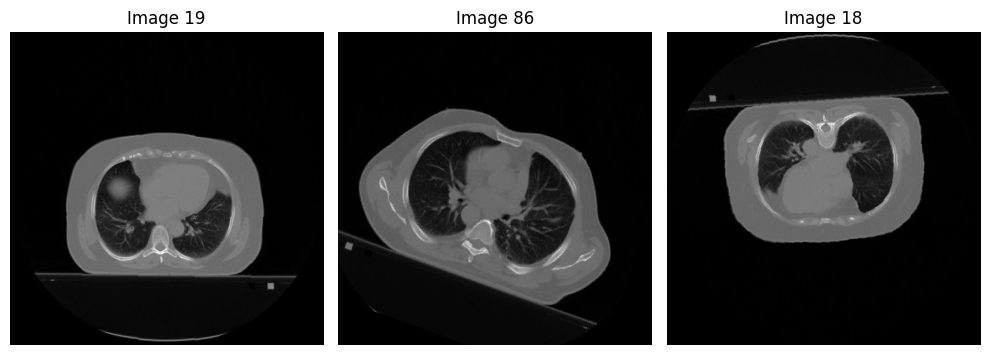

In [ ]:
fig, axs = plt.subplots(1, 3)
fig.set_figheight(4)
fig.set_figwidth(10)

selected_indices = np.random.randint(0, high=len(train_dataset), size=3)

for i in range(3):
    image_tensor, image_mask = train_dataset[selected_indices[i]]

    image_np = image_tensor.squeeze().numpy()
    axs[i].imshow(image_np, cmap='gray')

    axs[i].set_title(f"Image {selected_indices[i]}")
    axs[i].axis('off')

plt.tight_layout()
plt.show()

# Model

In [ ]:
class DoubleConv(nn.Module):
    """(conv => ReLU) * 2 with padding=1"""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

In [ ]:
class Down(nn.Module):
    """MaxPool followed by DoubleConv"""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.block(x)



In [ ]:
class Up(nn.Module):
    """Upsample → crop skip connection → concat → DoubleConv"""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.upconv = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):
        x1 = self.upconv(x1)

        # Crop x2 to match x1 due to valid conv
        diffY = x2.size(2) - x1.size(2)
        diffX = x2.size(3) - x1.size(3)
        x2 = x2[:, :, diffY//2: x2.size(2) - (diffY - diffY//2),
                     diffX//2: x2.size(3) - (diffX - diffX//2)]

        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)


In [ ]:

class UNet(nn.Module):
    """U-Net for binary segmentation (faithful to the paper and modified per homework)"""
    def __init__(self, in_channels=1, out_channels=1, base_channels=16):
        super().__init__()

        self.inc = DoubleConv(in_channels, base_channels)              # 16
        self.down1 = Down(base_channels, base_channels * 2)           # 32
        self.down2 = Down(base_channels * 2, base_channels * 4)       # 64
        self.down3 = Down(base_channels * 4, base_channels * 8)       # 128

        self.up1 = Up(base_channels * 16, base_channels * 8)          # 128
        self.up2 = Up(base_channels * 8, base_channels * 4)           # 64
        self.up3 = Up(base_channels * 4, base_channels * 2)           # 32

        self.outc = nn.Conv2d(base_channels, out_channels, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)      # 16
        x2 = self.down1(x1)   # 32
        x3 = self.down2(x2)   # 64
        x4 = self.down3(x3)   # 128

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)

        return self.outc(x)

# Train Model

In [ ]:
device = "cuda:0"
model = UNet().to(device)
model_8 = UNet(in_channels=1, out_channels=1, base_channels=8).to(device)
model_32 = UNet(in_channels=1, out_channels=1, base_channels=32).to(device)

## Hyperparameters

In [ ]:
device = "cuda:0"
lrRate = 1e-4
weightDecay = 1e-5
numberOfEpoch = 20
early_stop = 10
optimizer = optim.Adam(model.parameters(), lr=lrRate, weight_decay=weightDecay)

## Loss Function

In [ ]:
calc_loss = nn.BCEWithLogitsLoss()


In [ ]:
from ast import expr_context
def train(model, dataloaders, calc_loss, optimizer, numberOfEpoch, early_stop, device):

    best_model = copy.deepcopy(model.state_dict())
    best_f1 = 0.0
    early_stop_counter = 0

    train_loss_list = []
    val_loss_list = []
    val_f1_list = []

    for epoch in range(numberOfEpoch):
        print(f"\nEpoch {epoch+1}")

        for phase in ['train', 'val']:
            if phase == 'train':
              model.train()
            else:
               model.eval()

            running_loss = 0.0
            y_preds = []
            y_trues = []

            with tqdm(dataloaders[phase], unit="batch") as tbar:
                for images, masks in tbar:
                    tbar.set_description(f"{phase.capitalize()} Epoch {epoch+1}")

                    images = images.to(device)
                    masks = masks.to(device)

                    # Reset gradients
                    optimizer.zero_grad()

                    # Predict outputs
                    outputs = model(images)

                    # Calculate loss
                    loss = calc_loss(outputs, masks)

                    # Backpropagation and weight update
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                    # Update total epoch loss
                    running_loss += loss.item() * images.size(0)

                    # Metrics
                    probs = torch.sigmoid(outputs)
                    preds = (probs > 0.5).float()

                    y_preds.extend(preds.detach().cpu().numpy().flatten())
                    y_trues.extend(masks.detach().cpu().numpy().flatten())

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            f1 = f1_score(y_trues, y_preds, zero_division=0)
            precision = precision_score(y_trues, y_preds, zero_division=0)
            recall = recall_score(y_trues, y_preds, zero_division=0)

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} | F1: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f}")

            if phase == 'train':
                train_loss_list.append(epoch_loss)
            else:
                val_loss_list.append(epoch_loss)
                val_f1_list.append(f1)

                if f1 > best_f1:
                    best_f1 = f1
                    best_model = copy.deepcopy(model.state_dict())
                    early_stop_counter = 0
                else:
                    early_stop_counter += 1

                if early_stop_counter >= early_stop:
                    print(f"Early stopping at epoch {epoch+1} with best F1 = {best_f1:.4f}")
                    model.load_state_dict(best_model)
                    return best_model, train_loss_list, val_loss_list, val_f1_list

    model.load_state_dict(best_model)
    return best_model, train_loss_list, val_loss_list, val_f1_list

In [ ]:
best_model, train_loss_list, val_loss_list, val_f1_list = train(model, dataloaders, calc_loss, optimizer, numberOfEpoch, early_stop, device)


Epoch 1


Train Epoch 1: 100%|██████████| 15/15 [00:09<00:00,  1.64batch/s]


# Test Model

In [ ]:
def evaluate_models(labels_arr, predicted_arr):
    # Confusion matrix

    confusion_matrix = np.zeros((len(classDict), len(classDict)), dtype=int)
    for i, j in zip(labels_arr, predicted_arr):
        confusion_matrix[i, j] += 1

    classDict_names = [classDict.get(i) for i in range(len(classDict))]
    conf_matrix_df = pd.DataFrame(confusion_matrix, index= classDict_names, columns= classDict_names)
    sn.heatmap(conf_matrix_df, annot=True, cbar=False)
    plt.title("Simple CNN - With Augmentation")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.show()

    # Overall accuracy
    true_predictions = 0
    for i in range(len(labels_arr)):
        if labels_arr[i] == predicted_arr[i]:
            true_predictions += 1
    accuracy = true_predictions / len(labels_arr)
    print(f"Overall accuracy: {accuracy:.4f}")

    # Precision, recall, f1 score for each class
    for class_id, class_name in classDict.items():
        precision = 0
        recall = 0
        f1_score = 0

        true_pos = 0
        true_neg = 0
        false_pos = 0
        false_neg = 0

        for i in range(len(labels_arr)):
            if labels_arr[i] == class_id == predicted_arr[i]:
                true_pos += 1
            elif labels_arr[i] == class_id != predicted_arr[i]:
                false_neg += 1
            elif labels_arr[i] != class_id == predicted_arr[i]:
                false_pos += 1
            else: #labels_arr[i] != class_id != predicted_arr[i]:
                true_neg += 1

        if true_pos + false_pos != 0:
          precision = true_pos / (true_pos + false_pos)
        if true_pos + false_neg != 0:
          recall = true_pos / (true_pos + false_neg)
        if precision + recall != 0:
          f1_score = 2 * precision * recall / (precision + recall)

        print(f"Class {class_name}: \tPrecision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {f1_score:.4f}")

evaluate_models(np.array(labels), np.array(predictions))